In [11]:

!nvidia-smi


Fri Oct 16 11:06:58 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   32C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [12]:

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [13]:

!pip install -q -U ultralytics


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 38.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 11.3 MB/s eta 0:00:00


In [14]:

import ultralytics

print("Ultralytics version:", ultralytics.__version__)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics version: 8.4.178


In [15]:

from google.colab import files

uploaded = files.upload()

print("Uploaded files:")
for filename in uploaded:
    print(filename)


Saving Pothole.v1-raw.yolov8.zip to Pothole.v1-raw.yolov8.zip
Uploaded files:
Pothole.v1-raw.yolov8.zip


In [16]:

import os
import zipfile

zip_file = "/content/Pothole.v1-raw.yolov8.zip"
extract_dir = "/content/pothole_dataset"

if not os.path.exists(zip_file):
    raise FileNotFoundError(
        f"Dataset ZIP not found: {zip_file}. "
        "Check the filename from Step 4."
    )

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

print("Dataset extracted successfully!")
print("Dataset location:", extract_dir)


Dataset extracted successfully!
Dataset location: /content/pothole_dataset


In [17]:

from pathlib import Path

base = Path("/content/pothole_dataset")

yaml_files = list(base.rglob("*.yaml")) + list(base.rglob("*.yml"))

print("YAML files found:")
for file in yaml_files:
    print(file)


YAML files found:
/content/pothole_dataset/data.yaml


In [18]:

yaml_path = Path("/content/pothole_dataset/data.yaml")

if not yaml_path.exists():
    raise FileNotFoundError(
        "data.yaml is not at the expected location. "
        "Use the actual path printed in the previous cell."
    )

print(yaml_path.read_text())


train: ../train/images
val: ../valid/images
test: ../test/images

nc: 1
names: ['pothole']

roboflow:
  workspace: brad-dwyer
  project: pothole-voxrl
  version: 1
  license: ODbL v1.0
  url: https://universe.roboflow.com/brad-dwyer/pothole-voxrl/dataset/1


In [19]:

from pathlib import Path

base = Path("/content/pothole_dataset")

for split in ["train", "valid", "val", "test"]:
    image_dir = base / split / "images"
    label_dir = base / split / "labels"

    if image_dir.exists():
        print(f"\n{split.upper()}")
        print("Images:", len(list(image_dir.glob("*"))))
        print(
            "Labels:",
            len(list(label_dir.glob("*.txt")))
            if label_dir.exists() else 0
        )
    else:
        print(f"\n{split}: folder not found at {image_dir}")



TRAIN
Images: 465
Labels: 465

VALID
Images: 133
Labels: 133

val: folder not found at /content/pothole_dataset/val/images

TEST
Images: 67
Labels: 67


Training images found: 465


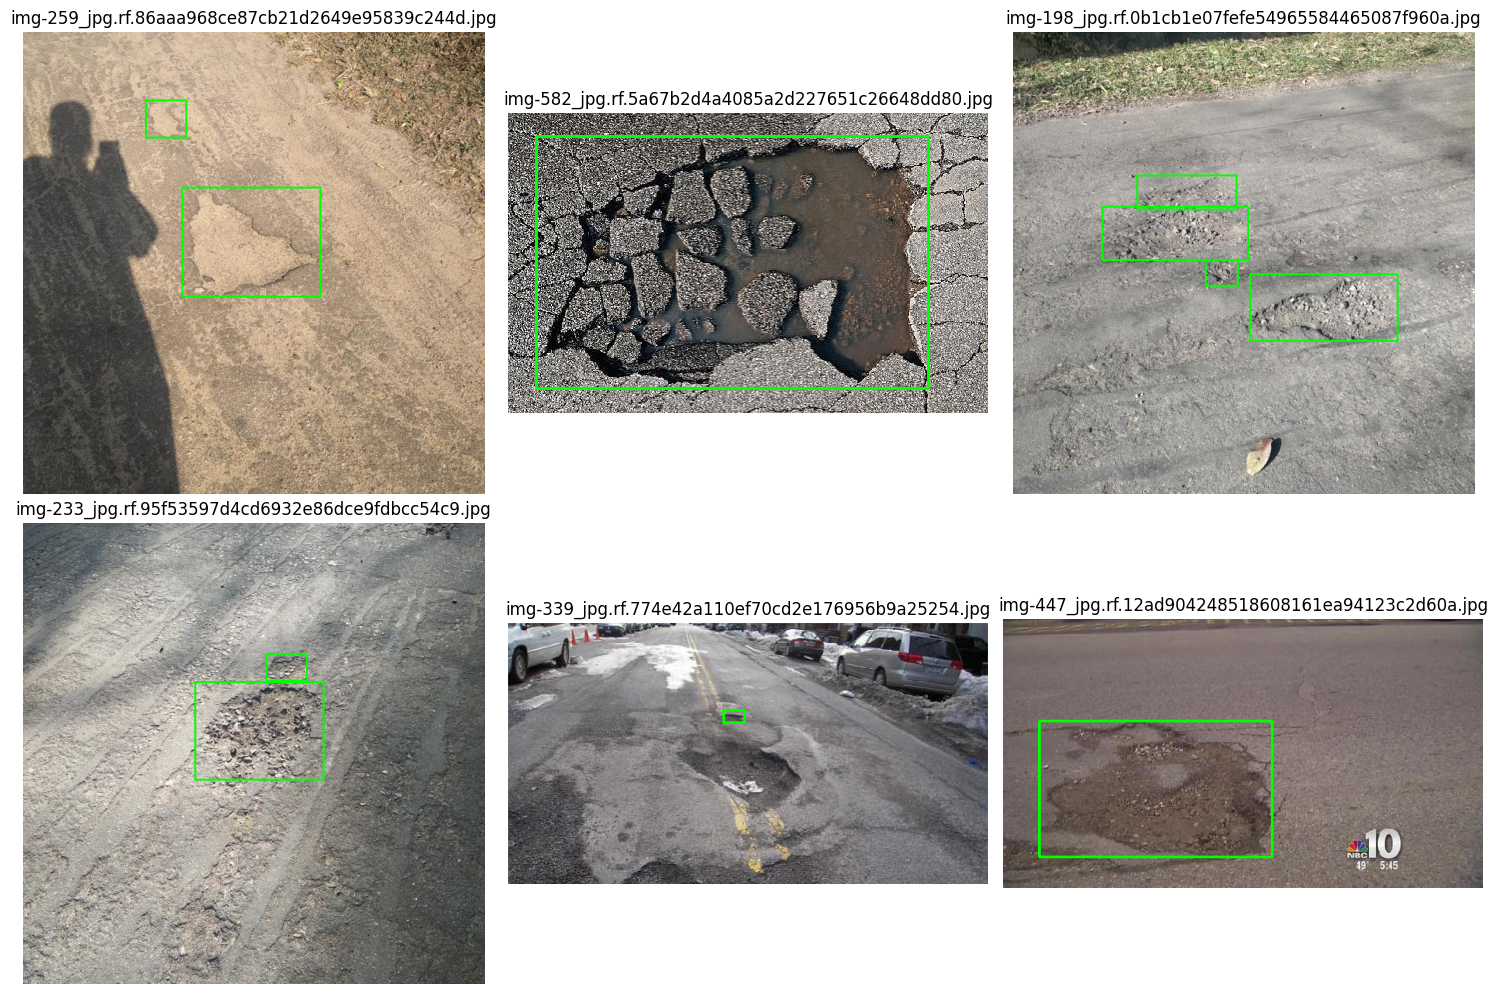

In [20]:

import cv2
import random
import matplotlib.pyplot as plt
from pathlib import Path

image_dir = Path("/content/pothole_dataset/train/images")
label_dir = Path("/content/pothole_dataset/train/labels")

image_files = [
    p for p in image_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
]

print("Training images found:", len(image_files))

if not image_files:
    raise ValueError("No training images found. Check the image path.")

sample = random.sample(image_files, min(6, len(image_files)))

plt.figure(figsize=(15, 10))

for i, img_path in enumerate(sample):
    image = cv2.imread(str(img_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    label_path = label_dir / f"{img_path.stem}.txt"

    if label_path.exists():
        h, w = image.shape[:2]

        for line in label_path.read_text().splitlines():
            parts = line.split()
            if len(parts) != 5:
                continue

            cls, xc, yc, bw, bh = map(float, parts)

            x1 = int((xc - bw / 2) * w)
            y1 = int((yc - bh / 2) * h)
            x2 = int((xc + bw / 2) * w)
            y2 = int((yc + bh / 2) * h)

            cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)

    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(img_path.name)
    plt.axis("off")

plt.tight_layout()
plt.show()


In [21]:
from ultralytics import YOLO
model = YOLO("yolov8n.yaml")

print("YOLOv8n initialized from scratch.")

YOLOv8n initialized from scratch.


In [22]:

results_v8 = model.train(
    data="/content/pothole_dataset/data.yaml",
    epochs=100,
    imgsz=640,
    batch=8,
    patience=20,
    project="/content/pothole_training",
    name="yolov8n_scratch",
    pretrained=False,
    device=0,
    workers=2,
    seed=42
)


Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pothole_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.yaml, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_scratch, nbs=64, nms=None, opset=None, optim

In [23]:

from pathlib import Path

weights_dir = Path(
    "/content/pothole_training/yolov8n_scratch/weights"
)

print("Available weight files:")

for weight_file in weights_dir.glob("*.pt"):
    print(weight_file, f"({weight_file.stat().st_size / 1e6:.1f} MB)")


Available weight files:
/content/pothole_training/yolov8n_scratch/weights/best.pt (6.2 MB)
/content/pothole_training/yolov8n_scratch/weights/last.pt (6.2 MB)


In [24]:

from ultralytics import YOLO

best_v8 = YOLO(
    "/content/pothole_training/yolov8n_scratch/weights/best.pt"
)

print("Scratch-trained weights loaded successfully!")


Scratch-trained weights loaded successfully!


In [25]:

val_results = best_v8.val(
    data="/content/pothole_dataset/data.yaml",
    split="val",
    imgsz=640,
    device=0
)


Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2697.8±1264.0 MB/s, size: 90.2 KB)
val: Scanning /content/pothole_dataset/valid/labels.cache... 133 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 133/133 46.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 3.1it/s 2.9s
                   all        133        330      0.735      0.655      0.732      0.429
Speed: 2.9ms preprocess, 8.5ms inference, 0.0ms loss, 2.7ms postprocess per image
Results saved to /content/runs/detect/val


In [26]:

test_results = best_v8.val(
    data="/content/pothole_dataset/data.yaml",
    split="test",
    imgsz=640,
    device=0
)


Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1789.0±818.3 MB/s, size: 71.8 KB)
val: Scanning /content/pothole_dataset/test/labels... 67 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 67/67 1.9Kit/s 0.0s
val: New cache created: /content/pothole_dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.1it/s 2.4s
                   all         67        154      0.672       0.69      0.705      0.432
Speed: 4.8ms preprocess, 6.0ms inference, 0.0ms loss, 6.1ms postprocess per image
Results saved to /content/runs/detect/val-2


In [27]:

results_v8_pred = best_v8.predict(
    source="/content/pothole_dataset/test/images",
    conf=0.50,
    imgsz=640,
    save=True,
    project="/content/pothole_predictions",
    name="yolov8n_scratch"
)

print("Prediction completed!")



image 1/67 /content/pothole_dataset/test/images/img-105_jpg.rf.3fe9dff3d1631e79ecb480ff403bcb86.jpg: 640x640 1 pothole, 11.9ms
image 2/67 /content/pothole_dataset/test/images/img-107_jpg.rf.2e40485785f6e5e2efec404301b235c2.jpg: 640x640 1 pothole, 11.9ms
image 3/67 /content/pothole_dataset/test/images/img-146_jpg.rf.61be25b3053a51f622a244980545df2b.jpg: 640x640 1 pothole, 11.9ms
image 4/67 /content/pothole_dataset/test/images/img-161_jpg.rf.211541e7178a4a93ec0680f26b905427.jpg: 640x640 1 pothole, 12.2ms
image 5/67 /content/pothole_dataset/test/images/img-168_jpg.rf.af3590e07b06b43e91fa53990ff94af3.jpg: 640x640 1 pothole, 11.9ms
image 6/67 /content/pothole_dataset/test/images/img-179_jpg.rf.8632eb0d9b75fefe144829e67b75015a.jpg: 640x640 2 potholes, 12.3ms
image 7/67 /content/pothole_dataset/test/images/img-195_jpg.rf.f77a8f4d432a9a89235168ff8e09a650.jpg: 640x640 3 potholes, 12.0ms
image 8/67 /content/pothole_dataset/test/images/img-196_jpg.rf.c1e105382a0bb8d329959cea45173cdf.jpg: 640x640

img-105_jpg.rf.3fe9dff3d1631e79ecb480ff403bcb86.jpg


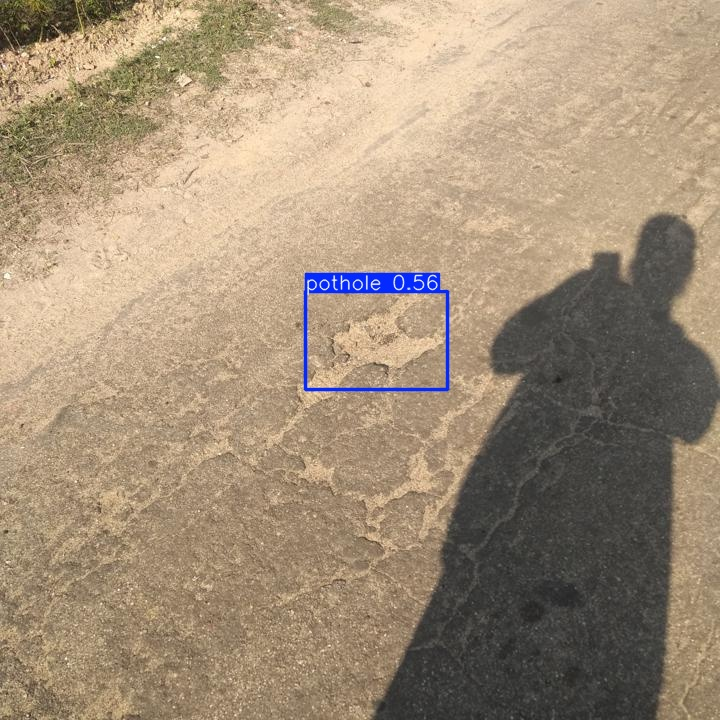

img-107_jpg.rf.2e40485785f6e5e2efec404301b235c2.jpg


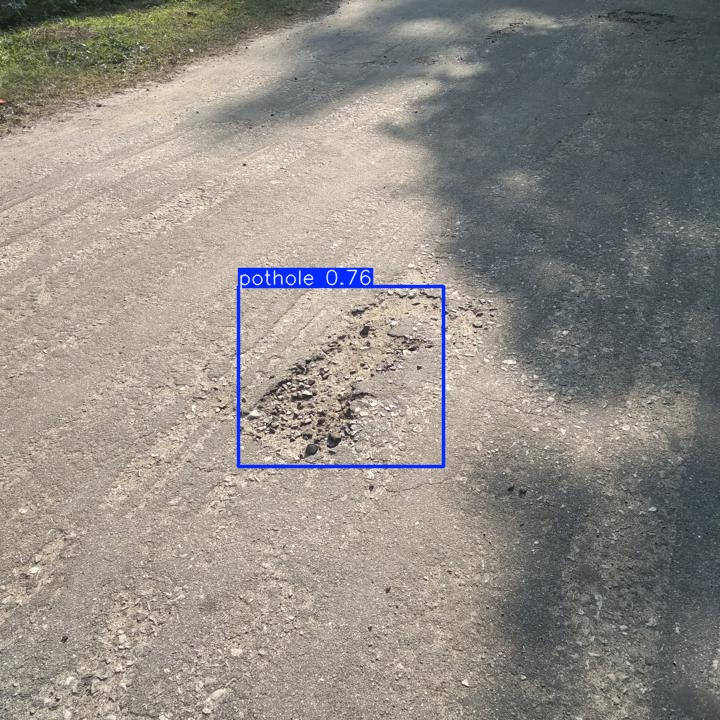

img-146_jpg.rf.61be25b3053a51f622a244980545df2b.jpg


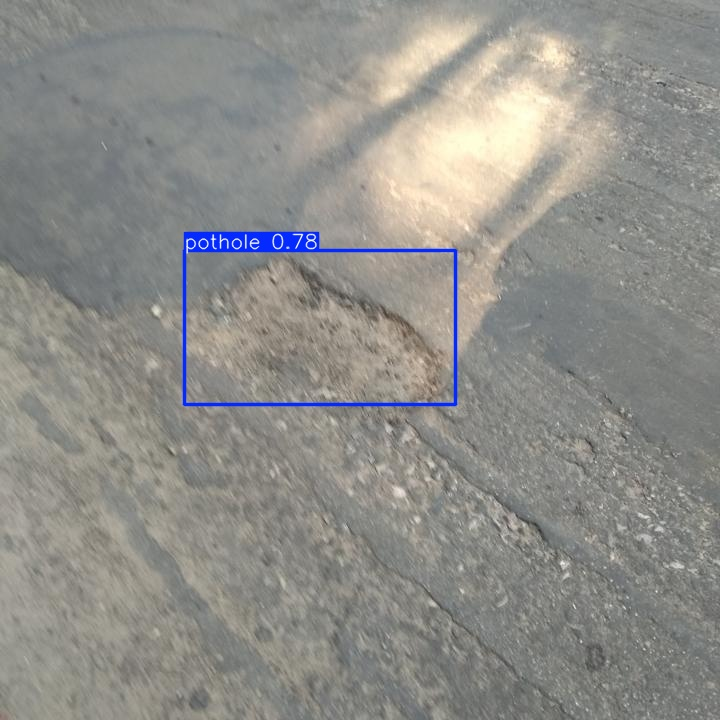

img-161_jpg.rf.211541e7178a4a93ec0680f26b905427.jpg


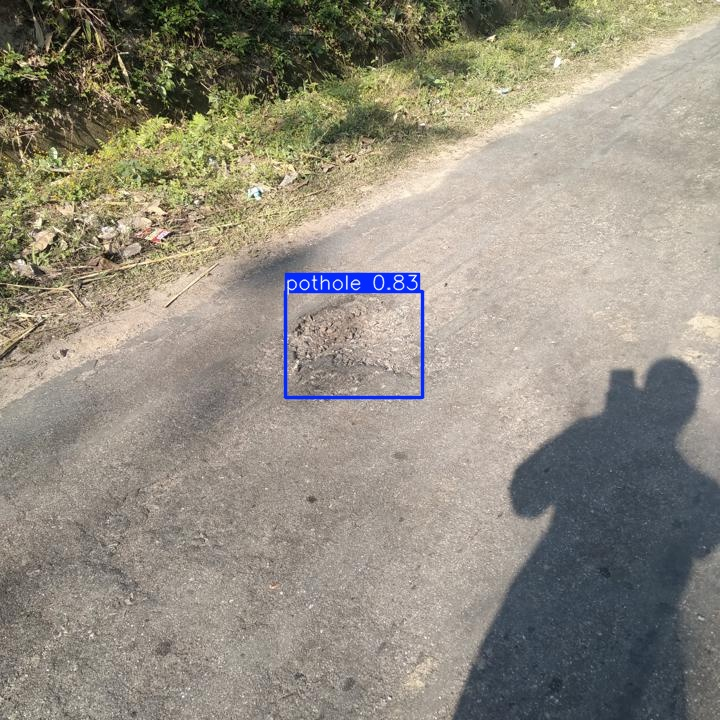

img-168_jpg.rf.af3590e07b06b43e91fa53990ff94af3.jpg


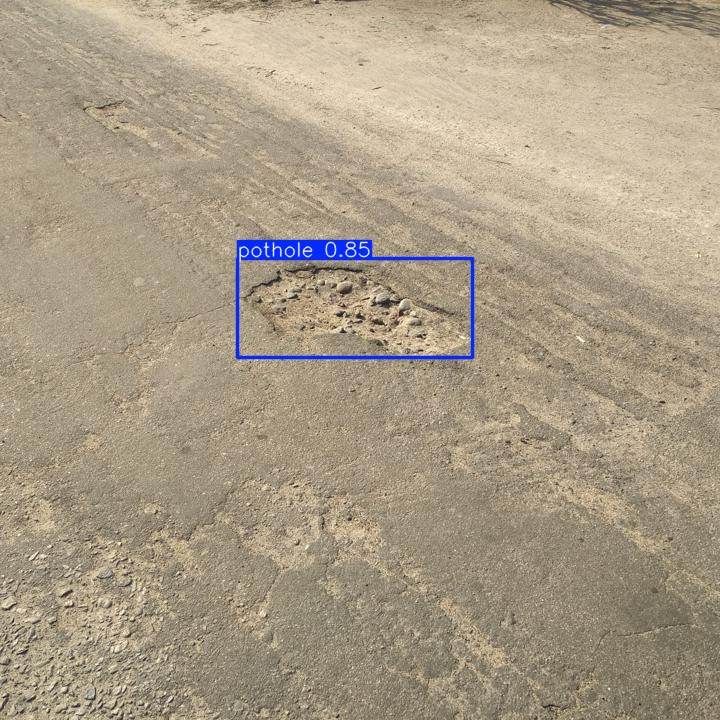

img-179_jpg.rf.8632eb0d9b75fefe144829e67b75015a.jpg


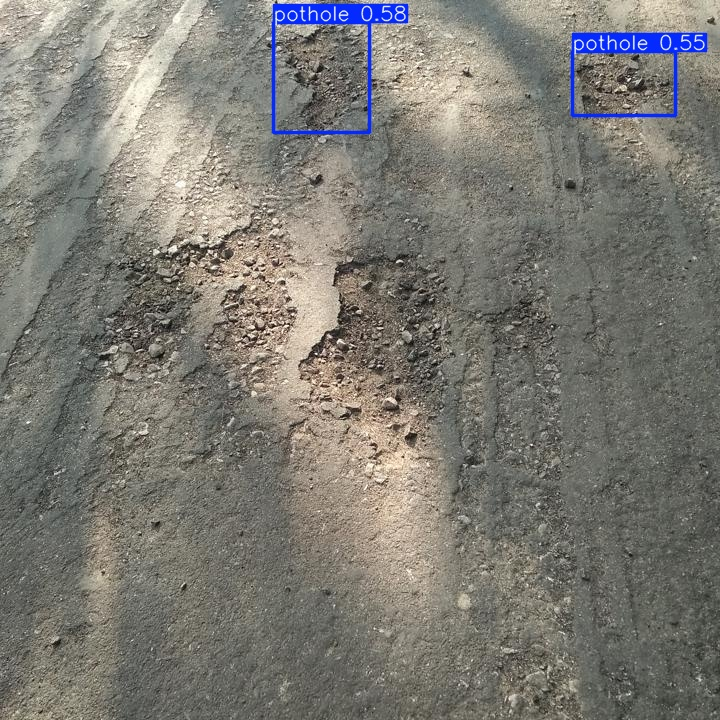

In [28]:

from pathlib import Path
from IPython.display import display, Image

prediction_dir = Path(
    "/content/pothole_predictions/yolov8n_scratch"
)

for img_path in sorted(prediction_dir.iterdir())[:6]:
    if img_path.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]:
        print(img_path.name)
        display(Image(filename=str(img_path)))


Saving Screenshot 2026-10-16 at 12.14.35 AM.png to Screenshot 2026-10-16 at 12.14.35 AM.png

image 1/1 /content/Screenshot 2026-10-16 at 12.14.35 AM.png: 416x640 1 pothole, 13.7ms
Speed: 2.2ms preprocess, 13.7ms inference, 2.1ms postprocess per image at shape (1, 3, 416, 640)
Results saved to /content/runs/detect/predict


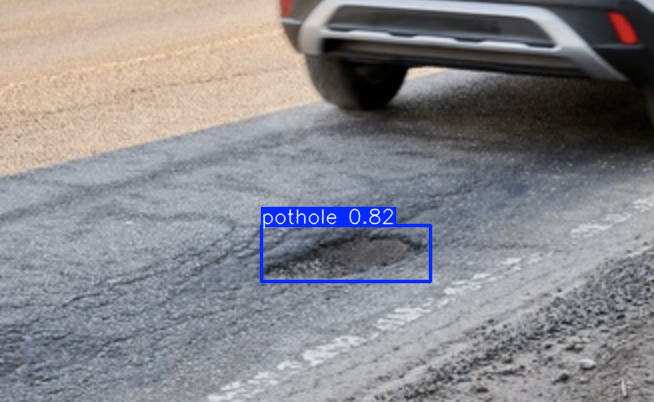

In [30]:

from google.colab import files
from IPython.display import display
from PIL import Image

uploaded = files.upload()

image_path = next(iter(uploaded.keys()))

predictions = best_v8.predict(
    source=image_path,
    conf=0.25,
    save=True
)

display(
    Image.fromarray(predictions[0].plot()[..., ::-1])
)


In [31]:

from google.colab import files

files.download(
    "/content/pothole_training/yolov8n_scratch/weights/best.pt"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
from ultralytics import YOLO

best_v8 = YOLO("/content/pothole_training/yolov8n_scratch/weights/best.pt")

metrics = best_v8.val(
    data="/content/pothole_dataset/data.yaml",
    split="test",
    imgsz=640,
    device=0
)

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1758.8±809.2 MB/s, size: 64.9 KB)
val: Scanning /content/pothole_dataset/test/labels.cache... 67 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 67/67 21.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.2it/s 2.3s
                   all         67        154      0.672       0.69      0.705      0.432
Speed: 4.5ms preprocess, 5.5ms inference, 0.0ms loss, 5.6ms postprocess per image
Results saved to /content/runs/detect/val-3
Precision: 0.6715252377463824
Recall: 0.6903168110220551
mAP50: 0.7054088431541776
mAP50-95: 0.43200046711743034


In [33]:
from google.colab import files
from pathlib import Path

if not Path("/content/best.pt").exists():
    uploaded = files.upload()
    print("Uploaded:", list(uploaded.keys()))

Files found:
val_batch1_pred.jpg
confusion_matrix_normalized.png
BoxP_curve.png
BoxPR_curve.png
val_batch2_pred.jpg
BoxR_curve.png
confusion_matrix.png
val_batch2_labels.jpg
val_batch1_labels.jpg
BoxF1_curve.png
val_batch0_labels.jpg
val_batch0_pred.jpg


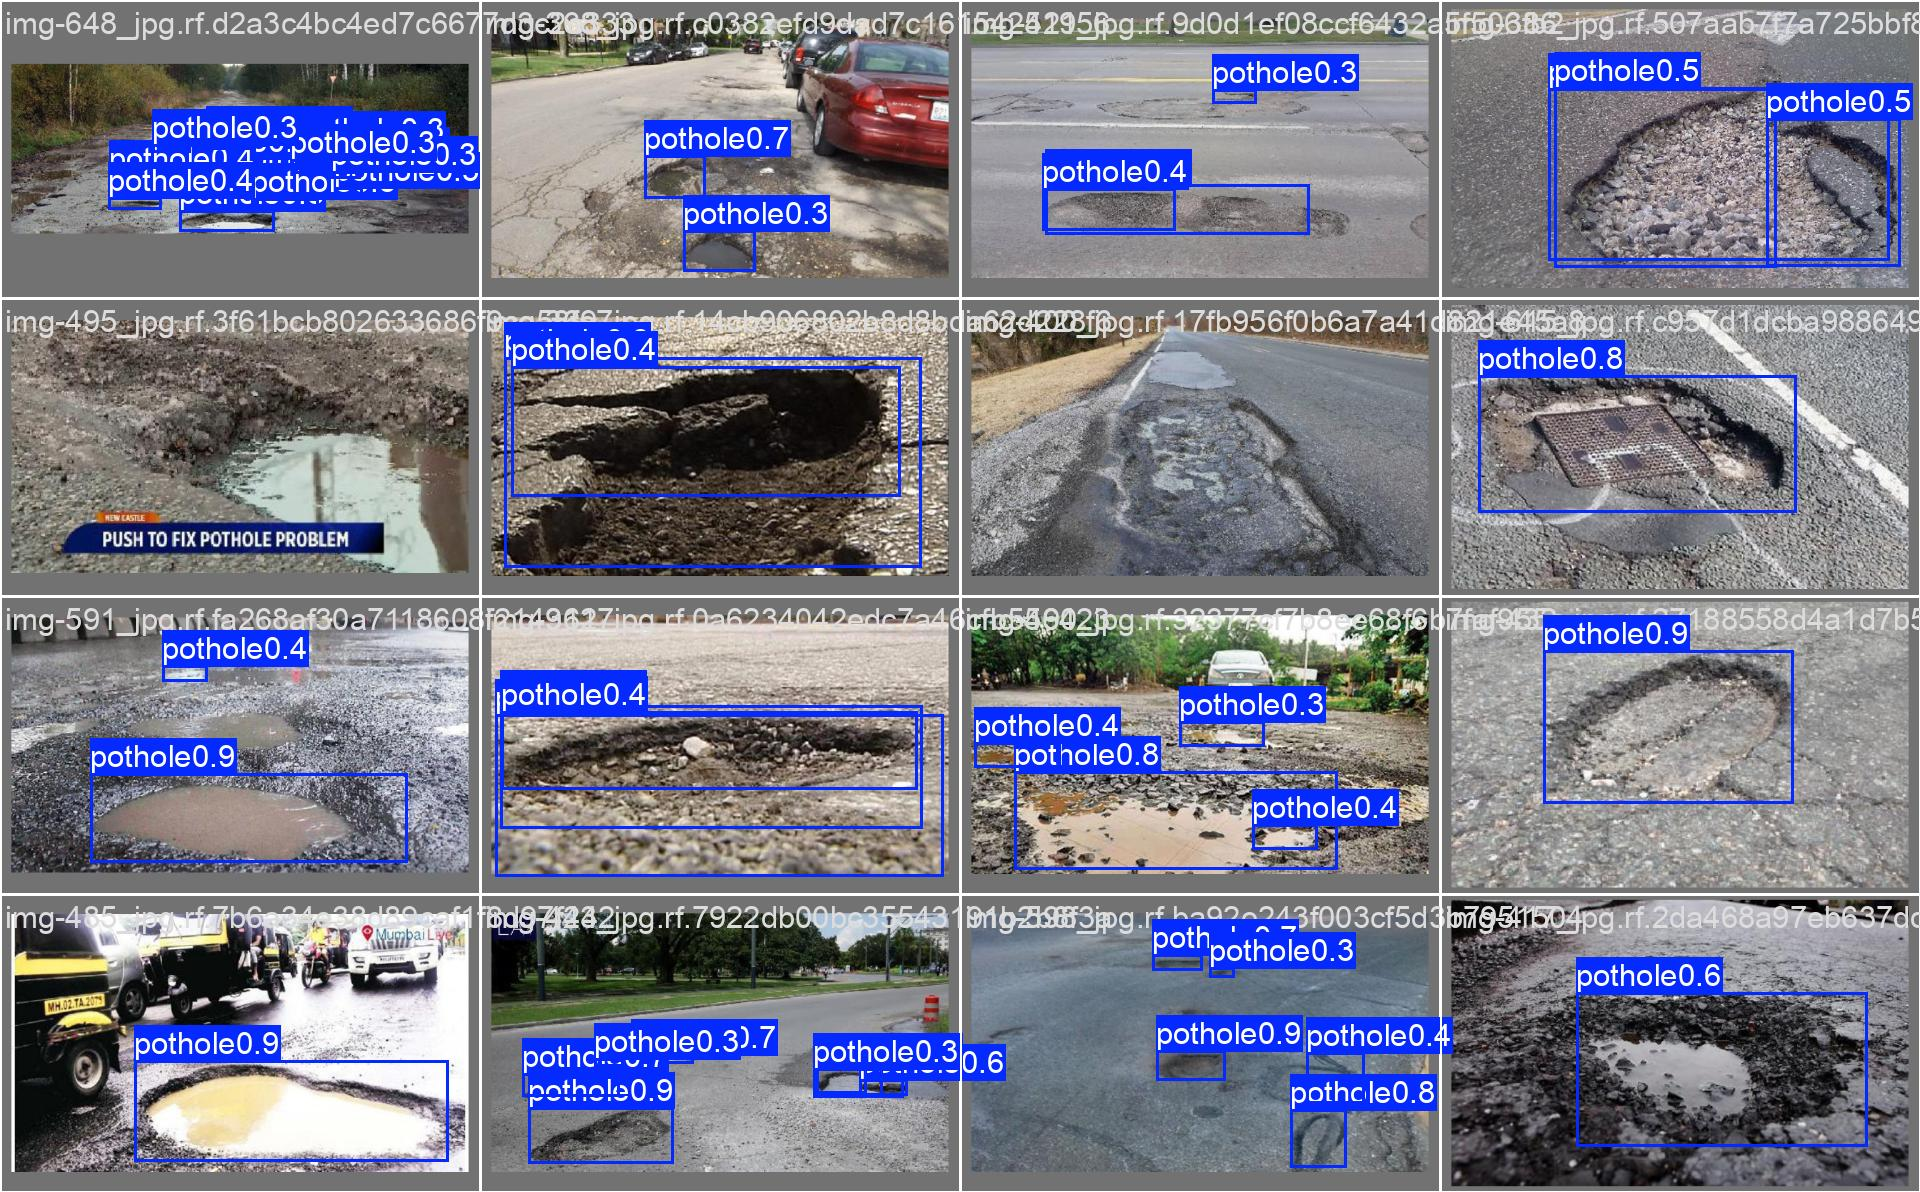

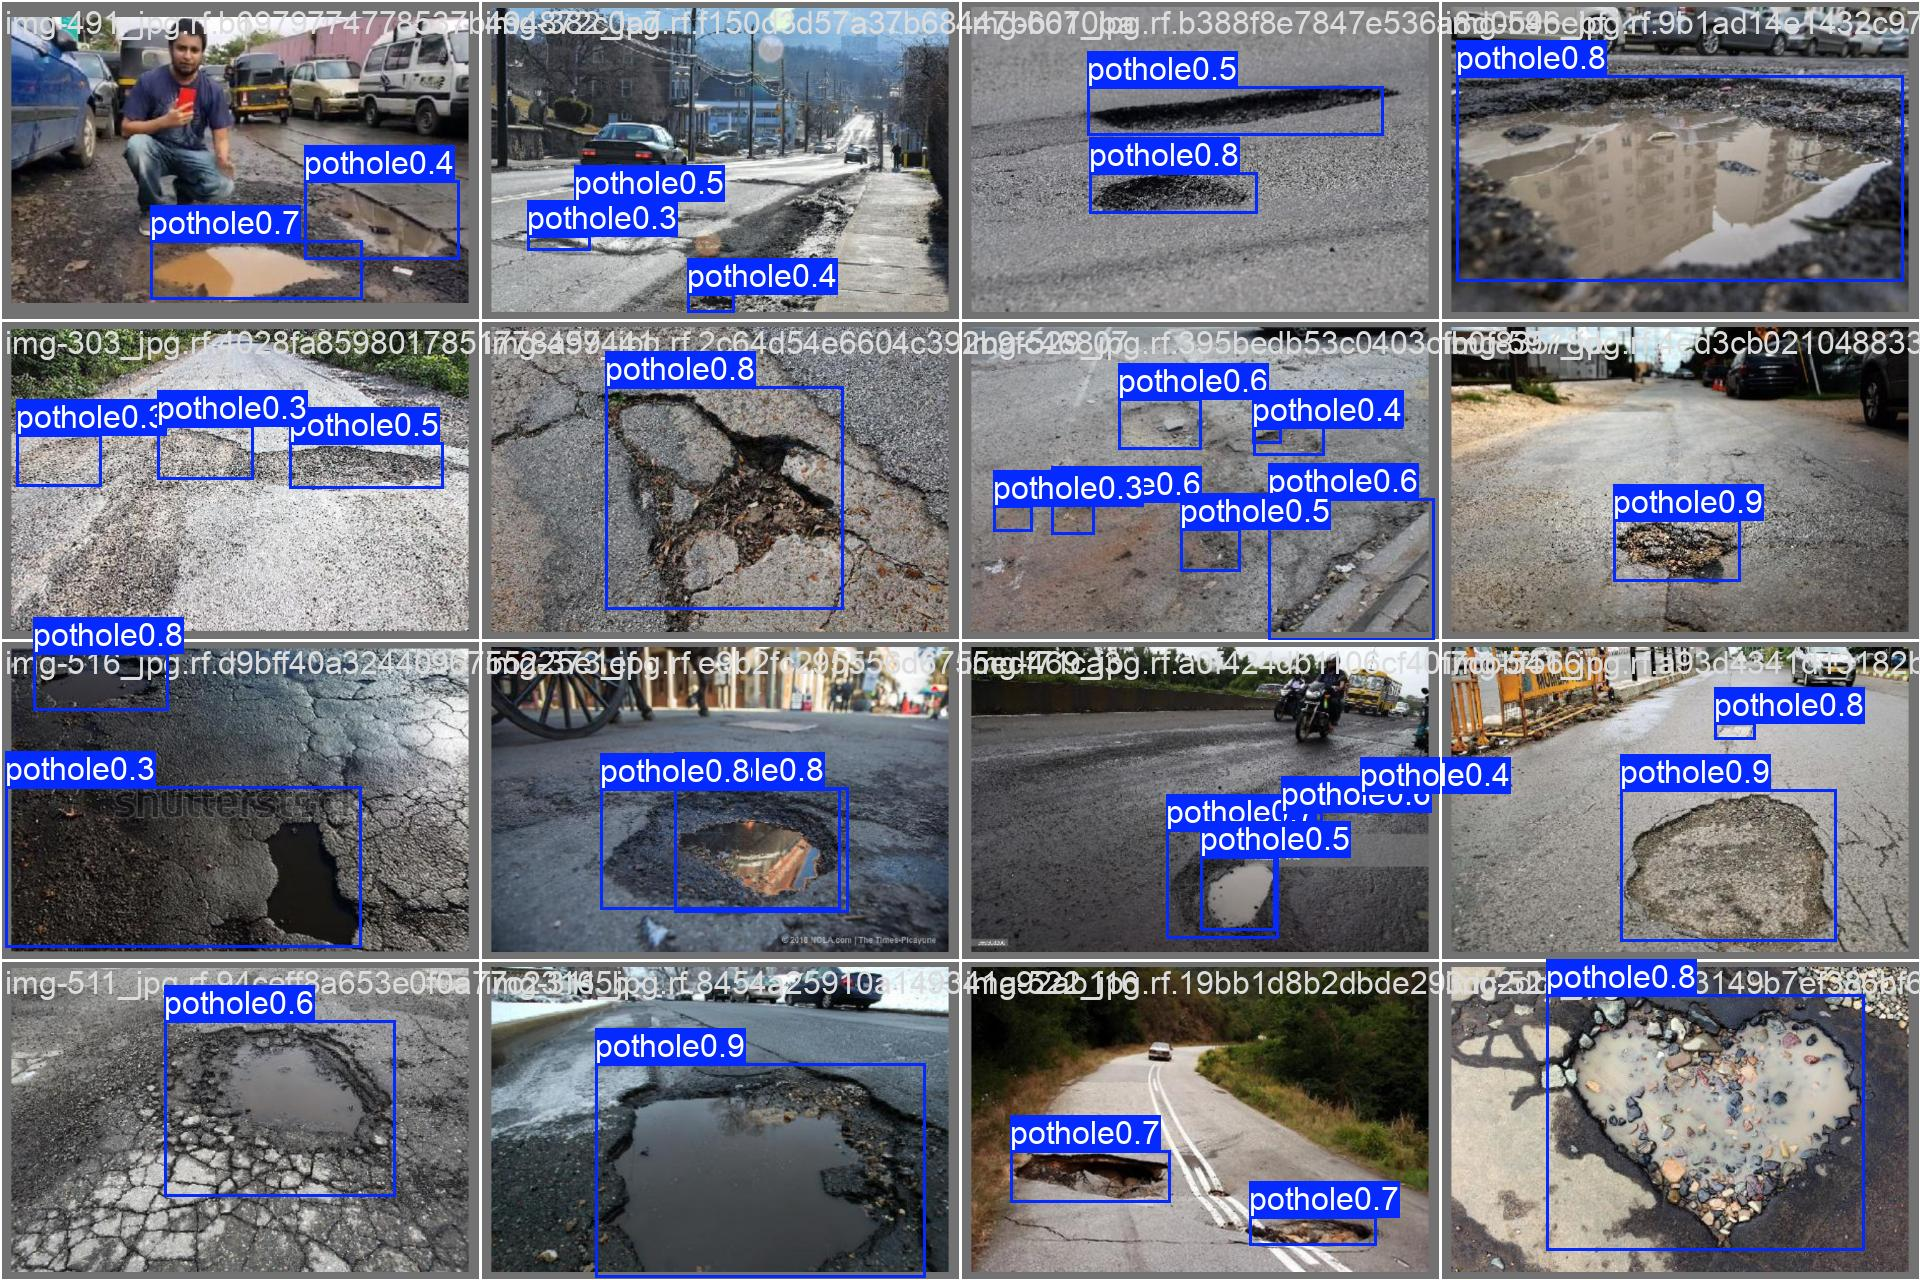

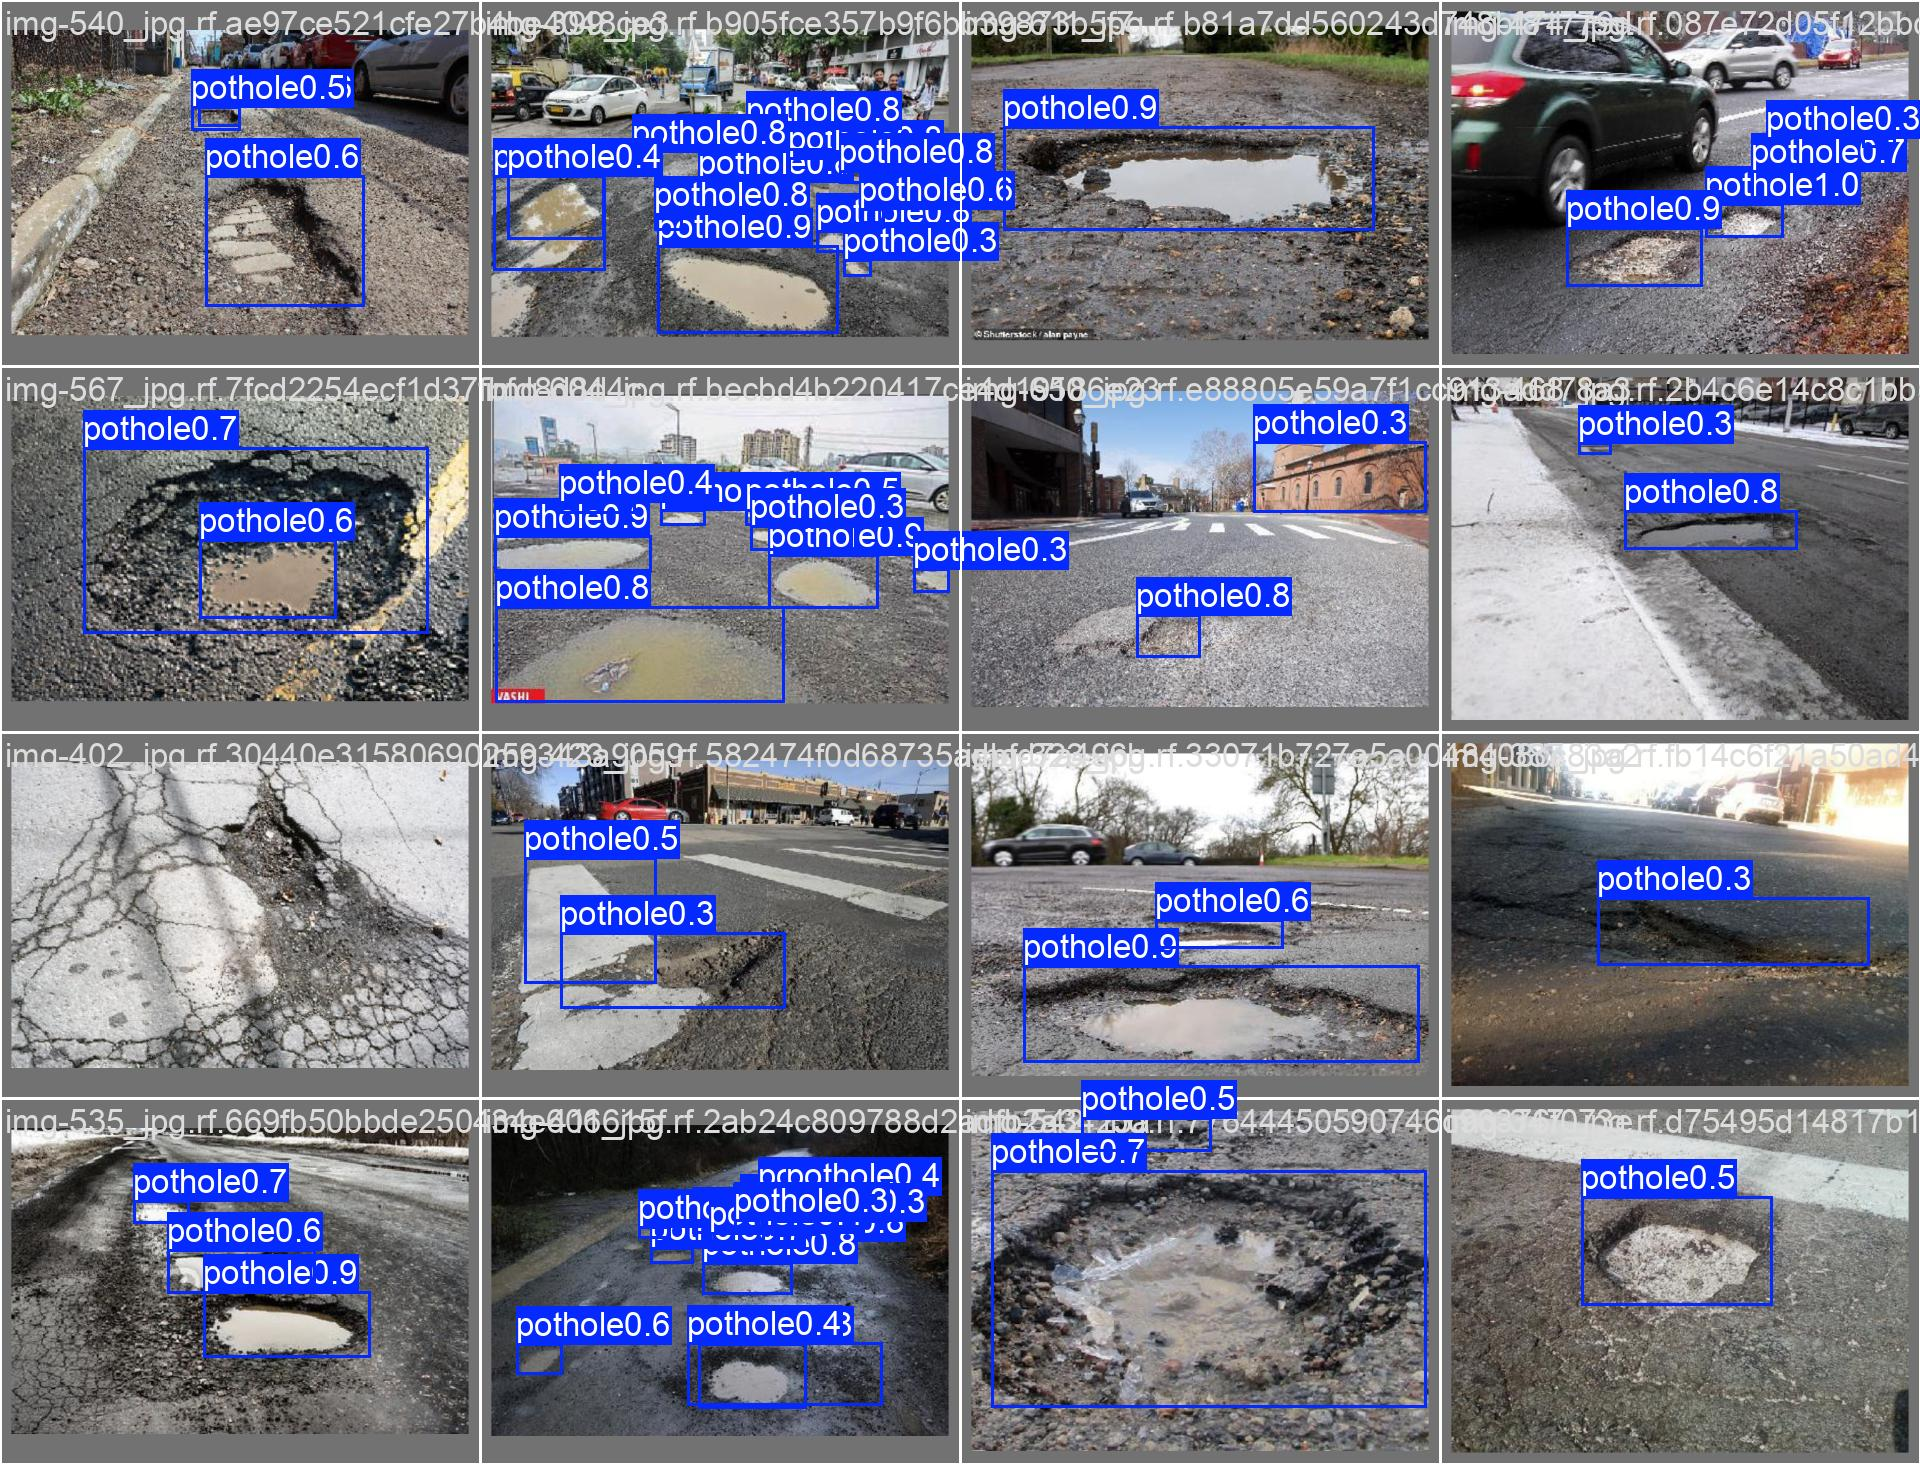

In [34]:
from pathlib import Path
from IPython.display import display, Image

results_dir = Path("/content/runs/detect/val")

print("Files found:")
for p in results_dir.iterdir():
    print(p.name)

for p in sorted(results_dir.glob("*pred*.jpg")):
    display(Image(filename=str(p)))

In [35]:

from pathlib import Path
import zipfile
from google.colab import files

# Search common YOLO output directories
search_dirs = [
    Path("/content/runs/detect"),
    Path("/content/pothole_training"),
    Path("/content/pothole_predictions"),
]

image_files = []

for folder in search_dirs:
    if folder.exists():
        for path in folder.rglob("*"):
            if path.is_file() and path.suffix.lower() in {
                ".png", ".jpg", ".jpeg"
            }:
                if "val" in str(path).lower() or "predict" in str(path).lower():
                    image_files.append(path)

print("Prediction/validation images found:", len(image_files))

if image_files:
    zip_path = "/content/pothole_result_images.zip"

    with zipfile.ZipFile(zip_path, "w") as archive:
        for path in image_files:
            archive.write(path, arcname=path.name)

    files.download(zip_path)
else:
    print("No saved images found. We can save new results from the screenshot/model.")


Prediction/validation images found: 110


/usr/lib/python3.13/zipfile/__init__.py:1661: UserWarning: Duplicate name: 'val_batch1_pred.jpg'
  return self._open_to_write(zinfo, force_zip64=force_zip64)
/usr/lib/python3.13/zipfile/__init__.py:1661: UserWarning: Duplicate name: 'confusion_matrix_normalized.png'
  return self._open_to_write(zinfo, force_zip64=force_zip64)
/usr/lib/python3.13/zipfile/__init__.py:1661: UserWarning: Duplicate name: 'BoxP_curve.png'
  return self._open_to_write(zinfo, force_zip64=force_zip64)
/usr/lib/python3.13/zipfile/__init__.py:1661: UserWarning: Duplicate name: 'BoxPR_curve.png'
  return self._open_to_write(zinfo, force_zip64=force_zip64)
/usr/lib/python3.13/zipfile/__init__.py:1661: UserWarning: Duplicate name: 'val_batch2_pred.jpg'
  return self._open_to_write(zinfo, force_zip64=force_zip64)
/usr/lib/python3.13/zipfile/__init__.py:1661: UserWarning: Duplicate name: 'BoxR_curve.png'
  return self._open_to_write(zinfo, force_zip64=force_zip64)
/usr/lib/python3.13/zipfile/__init__.py:1661: UserWarn

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:
import ultralytics
import numpy
import cv2
import PIL
import matplotlib
import pandas
import yaml

print("ultralytics:", ultralytics.__version__)
print("numpy:", numpy.__version__)
print("opencv:", cv2.__version__)
print("Pillow:", PIL.__version__)
print("matplotlib:", matplotlib.__version__)
print("pandas:", pandas.__version__)
print("PyYAML:", yaml.__version__)

ultralytics: 8.4.178
numpy: 2.1.3
opencv: 4.14.0
Pillow: 11.3.0
matplotlib: 3.10.0
pandas: 2.2.3
PyYAML: 6.0.3
